# Estudio y discusión del notebook 29

El ejemplo central es $V_{\rm bin}>V_{\rm lam}$ con tres personas. El par y la matriz son puntos de partida recuperados del notebook 28. La búsqueda inicial fue local; la ampliación posterior sí incluyó Hermeneuta y produjo la familia que se aproxima a $10/9$, descrita al final de estas notas.

Actualización del 14 de octubre: el [plan para el martes 20](../../docs/notes/2026-10-14-plan-semana.md) añade el argumento de información en $q=1/2$ y la comparación de greedy y rollout con el óptimo laminar. El notebook conserva sus cinco bloques; no contiene todavía esa nueva malla.

## Guion de 10 minutos

1. Par · 1 minuto. «Contar permite resolver un par y gastar la prueba restante fuera de él». Reconstruye por qué las ramas tienen valores 2.3, 1 y 0.3.
2. Cotas · 1 minuto. «Las cotas de Francisco permiten que el binario gane; no dicen si ocurre». Distingue una cota de una separación observada.
3. Contraejemplo · 4 minutos. «Ya encontramos esa separación con tres personas». Explica por qué AC sigue siendo atractivo tras AB positivo, qué impide la laminaridad y cómo se certificó su óptimo.
4. Matriz · 2 minutos. «Varias ecuaciones de conteo identifican más que una jerarquía laminar en este caso». Reconstruye la firma (1,1,2) y pregunta por el argumento dinámico que falta.
5. Reglas · 2 minutos. «Ya distinguimos la pérdida de la restricción de la pérdida de la heurística». En el contraejemplo no se corrige la primera mejorando una regla laminar.

## Tu orden de estudio

Empieza por el bloque 3: dibuja AB y sus continuaciones en el iPad; calcula cada probabilidad antes de mirar las fórmulas. Sigue con el intercambio general del bloque 1. Después trabaja el bloque 4 y la pregunta nueva: ¿cuánta información permiten B pruebas con como máximo G+1 resultados cada una? Termina distinguiendo greedy, rollout y nuestras reglas con planificación. Haz una pasada oral de 10 minutos sin leer el texto.

## Contraejemplo: comprobación a mano

$q_A=19/20$, $q_B=q_C=4/5$, $B=G=2$, $u_i=1$. Los tres modelos tienen los mismos recursos.

AB negativo tiene probabilidad $0.95\times0.8=0.76$. C sigue sano con probabilidad 0.8. La contribución de esa rama es $0.76(2+0.8)=2.128$ en las dos políticas.

AB positivo y AC negativo significa exactamente A sano, B infectado y C sano. Su probabilidad conjunta es $0.95(0.2)(0.8)=0.152$. Es la multiplicación más sencilla: dos sanos acreditados por $0.152$ de probabilidad. Así, la política binaria vale $2.128+2(0.152)=2.432$.

Para dibujar el árbol con probabilidades condicionales: $P(AC^-\mid AB^+)=0.152/0.24=19/30$. A queda sano con probabilidad $0.19/0.24=19/24$, y C sigue independiente con probabilidad $4/5$. Por eso probar AC sigue teniendo sentido.

El laminar observa $R=1$ con probabilidad $0.95(0.2)+0.05(0.8)=0.23$ y puede asegurar un sano probando A. Con $R=2$, probabilidad $0.01$, prueba C y cobra 0.8 en promedio. Total: $2.128+0.23+0.008=2.366$.

## ¿Cómo sabemos que no hay una política laminar mejor?

Hay seis primeras pruebas. Enumerar todas sus continuaciones legales da: A → 2.23; B o C → 2.32; AB o AC → 2.366; BC → 2.246. Su máximo es 2.366. Este cálculo directo coincide con el Bellman sobre perfiles y con el solver de átomos residuales.

Incluso sin certificar el óptimo binario, una política binaria de valor 2.432 ya separaría las clases del óptimo laminar 2.366. Además, dos solvers binarios coinciden en que esa política es óptima.

No atribuimos esta separación a un beneficio de tener menos información. El general siempre puede imitar al binario y aquí obtiene 2.448. Lo que cuesta es restringir las pruebas permitidas.

## Una región, además de un punto

$n=3$, $B=G=2$, $u_i=1$, $q_A=0.95$, $q_B=q_C=t$. Se evaluaron exactamente $t=0.05,0.06,\ldots,0.99$.

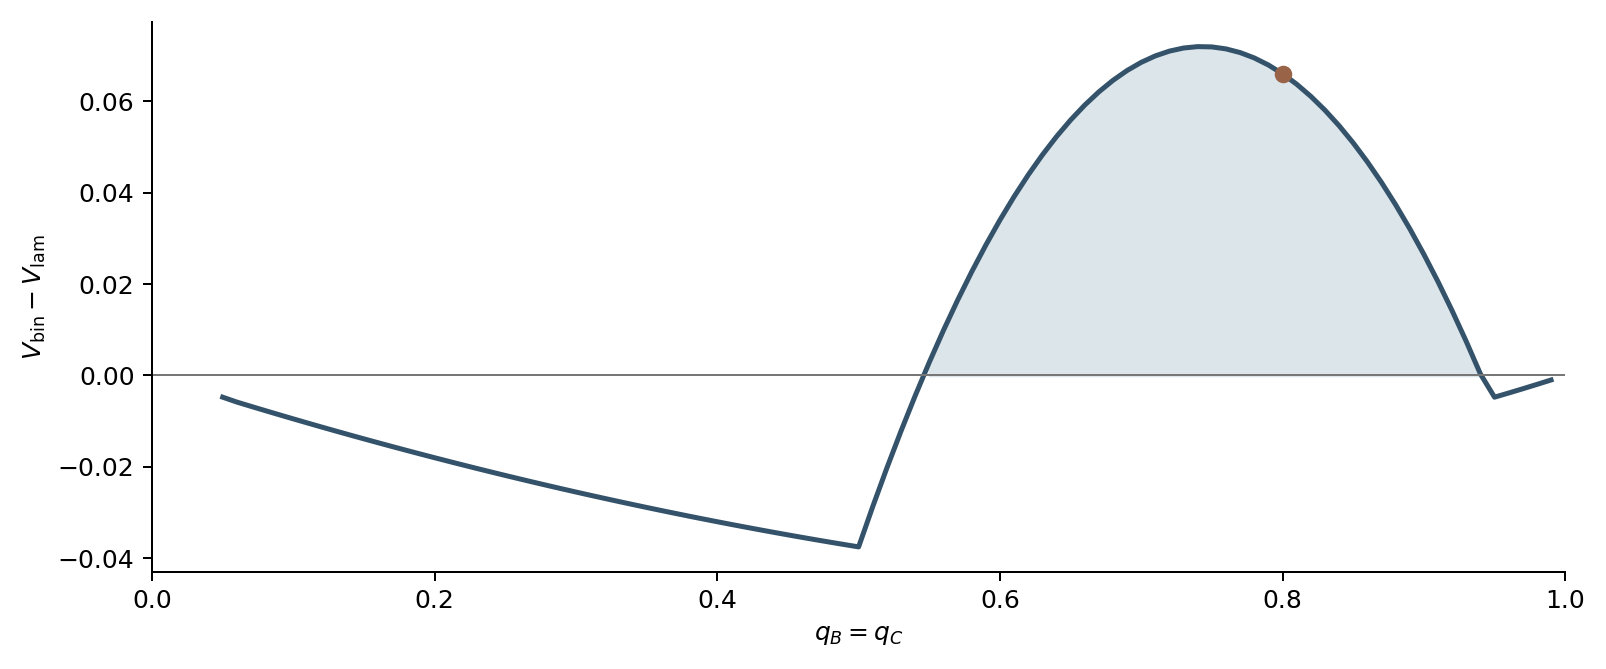

En esta malla, el binario gana en los 40 puntos de $0.55$ a $0.94$. El ejemplo presentado es $t=0.80$. Es una sección de una familia heterogénea: no describe todos los regímenes de probabilidad ni localiza fronteras continuas exactas.

La búsqueda amplia examinó 1.386 instancias exactas: 208 con binario superior, 1.142 con laminar superior y 36 empates, sin casos truncados. Incluye una malla homogénea, propuestas heterogéneas y mutaciones de buenos candidatos. Es una búsqueda dirigida, no una muestra representativa; esos porcentajes no miden cuál clase gana «normalmente».

También se encontró separación homogénea: $n=5$, $B=3$, $G=4$, $q=0.95$, $u_i=1$. Binario 4.65554625; laminar 4.6462125. El ejemplo de tres personas se eligió por su explicación más corta.

## De las cotas a una posible prueba

Para $V_{\rm aug}\le G V_{\rm bin}$, ordena $m_i=q_i u_i$ y llama $T_k$ a la suma de los $k$ mayores. Antes de probar por primera vez a una persona, su estado no influye en que la política decida incluirla: esa decisión depende de los otros estados y de la aleatoriedad independiente. Si $s_i$ es su probabilidad de aparecer, su utilidad esperada acreditada es a lo sumo $m_i s_i$. Como $\sum_i s_i\le BG$, resulta $V_{\rm aug}\le T_{BG}\le G T_B\le G V_{\rm bin}$. Se requiere independencia y priors interiores para que un sano no probado no quede acreditado por inferencia.

Para el factor cuatro: binario dinámico ≤ 2 × binario estático con pools arbitrarios ≤ 4 × binario estático disjunto ≤ 4 × aumentado laminar. [El paper de Nic, introducción y §5](https://arxiv.org/html/2601.22419v2), prueba el primer factor y atribuye el segundo a Finster et al. El último paso es inclusión de políticas.

Acercarse a $G$ requiere contabilizar las pruebas de localización. Si cubrimos $k$ grupos de tamaño $G$ y reservamos $\ell=\lceil\log_2G\rceil$ pruebas para localizar un sano, entonces $B=k+\ell$, $n=kG$, y la política laminar garantiza al menos $1-(1-q)^{kG}$. Para $q\le1/2$, el óptimo binario homogéneo es $Bq$ cuando $n\ge B$, por [Teorema 3.3](https://arxiv.org/html/2601.22419v2#S3.SS2). El cociente de esa garantía con $Bq$ tiende a $kG/(k+\ell)$ cuando $q\to0$. Después, $k\to\infty$ aproxima $G$. No es $G$ para $k$ fijo.

En la matriz del bloque 4, las ecuaciones son $z_A+z_B+z_C=1$, $z_A+z_B+z_D=1$, $z_A+z_C+z_D=2$, con $z_i\in\{0,1\}$. Las dos primeras dan $z_C=z_D$; la tercera obliga $z_C=z_D=1$, $z_A=0$, y entonces $z_B=0$. Son sumas enteras, no módulo dos.

Para convertir el ejemplo de matrices en una separación asintótica faltan dos piezas: una familia admisible de diseños con pocos tests y una cota para cualquier política dinámica laminar. La propuesta $V_{\rm lam}\le KB$ es una pregunta de investigación. Una cota para planes estáticos o para diagnóstico completo no la sustituye.

## Próximos pasos para discutir con Francisco

1. Revisar la construcción general del par en la nota de la proposición, con sus hipótesis y fronteras. La revisión computacional no sustituye la lectura y validación de Héctor.
2. Consolidar las comprobaciones independientes del solver y los CSV del plan del 14 de octubre.
3. Explicar el contraejemplo de tres personas y después la familia de cuatro: ¿qué amplifica la ventaja? No sabemos si $10/9$ es una cota superior universal.
4. En $q=1/2$, $u_i=1$, estudiar primero la cota de información y ampliar la malla en G. La cota $V_{\rm lam}\le KB$ y las construcciones de matrices quedan en el frente de Francisco según el plan semanal.
5. Comparar greedy y rollout sobre una jerarquía fija con el óptimo laminar por trayectoria. No son $\pi_L$ y $\pi_{\rm ratio}$; la pérdida puede incluir tanto la jerarquía elegida como la regla de decisión.

Preguntas para abrir la discusión: «¿Este ejemplo responde a la separación que buscabas?», «¿Qué parámetro debería amplificar la ventaja de volver a incluir A?», «¿Nos interesa una garantía con G fijo o independiente de G?» y «¿Qué cantidad asociada a los bloques laminares podría acotar la utilidad ganada por prueba?».

## Reproducibilidad

Desde la raíz del repositorio:

```sh
python -m augmented.experimento_sesion_29
python augmented/notebooks/build_29_sesion.py
python -m pytest augmented/tests_bellman_binario_exacto.py -q
```

Los experimentos están en `results/sesion_2026-10-12/evidencia_29.json`; la búsqueda completa, en `busqueda/cases.jsonl` y `busqueda/summary.json`. Los árboles se evaluaron independientemente sobre cada perfil, con aritmética racional. El binario se contrastó además con el solver clásico; el laminar, con el solver de átomos.

Para continuar buscando, el programa acepta una carpeta nueva y límites de tiempo:

```sh
python -m augmented.busca_binario_vs_laminar --out results/otra_busqueda --seconds 600 --random 1000 --adaptive 200
```

Es búsqueda de instancias con evaluadores fijos, semilla y registro de cada intento. No es una ejecución del agente de Karpathy ni modifica los solvers para mejorar resultados. Ese comando reproduce la primera etapa local; la ampliación posterior sí utilizó Hermeneuta. Sus registros y certificados están en `results/sesion_2026-10-12/brecha_ampliada/`.

## La familia posterior: una ventaja que se aproxima al 11.11%

$n=4$, $B=G=2$, $q=(s,1/2,1/2,s)$, $u=(1,3,3,2)$, con $19/20\le s<1$. Aquí también cambian las utilidades respecto del ejemplo de tres personas.

$$V_{\rm bin}=\frac52s(1+s),\qquad V_{\rm lam}=3+\frac32s^2.$$

La política binaria abre BD: si sale negativo prueba AC; si sale positivo prueba AD. La laminar abre BC: si el conteo es 1, prueba B; si es 0 o 2, prueba AD. La primera aprovecha la posibilidad de reutilizar D en otro grupo; la segunda combina la resolución del par BC con la oportunidad de acreditar AD.

En $s=0.99$, binario obtiene 4.92525 y laminar 4.47015. Al acercar s a 1, el cociente binario/laminar tiende a $10/9$. Es una separación alcanzable como límite, no una prueba de que ningún caso la supere. No se sustituye $s=1$: entonces A y D ya son sanos conocidos y el valor laminar cambia.

La comprobación simbólica compara todas las primeras pruebas y continuaciones mediante 454 desigualdades en el intervalo. Se reproduce con `python -m pytest augmented/tests_busqueda_brecha_ampliada.py -q`; la nota de resultados explica las ramas y enlaza el certificado. La búsqueda numérica sugirió la familia; el certificado comprueba sus fórmulas.